# Object Recognition with Open Images v7 and Webcam

In this notebook we prepare a dataset from **Open Images v7** using **FiftyOne**, build multi-label targets from the annotated objects, and adapt a **ResNet50** model with transfer learning and fine-tuning in **TensorFlow/Keras**.

The final model is intended to recognize everyday objects from a live webcam feed.

**Workflow:**
- Choose target classes
- Download train and validation subsets
- Inspect and filter the dataset
- Build multi-hot labels and merge duplicate images
- Prepare the TensorFlow data pipeline
- Build and train a ResNet50 transfer-learning model
- Fine-tune the top layers
- Evaluate and visualize the training process

In [1]:
import fiftyone as fo
import fiftyone.zoo as foz

In [2]:
print(fo.list_datasets())

You are running the oldest supported major version of MongoDB. Please refer to https://deprecation.voxel51.com for deprecation notices. You can suppress this exception by setting your `database_validation` config parameter to `False`. See https://docs.voxel51.com/user_guide/config.html#configuring-a-mongodb-connection for more information
['train_dataset', 'validation_dataset']


## Target classes

We use **30 everyday classes** that are likely to appear in front of a webcam:

- **Electronics:** mobile phone, laptop, keyboard, mouse, headphones, monitor, remote control, camera
- **Office items:** book, pen, scissors, calculator
- **Kitchen and tableware:** mug, bottle, coffee cup, plate, bowl, spoon, fork, knife
- **Personal items:** glasses, watch, backpack, clock
- **Fruit:** banana, apple, orange
- **People:** person, human face, human hand

The class names must match the Open Images names used in the `labels` list.

In [3]:
labels = [
    "Mobile phone", "Laptop", "Computer keyboard", "Computer mouse",
    "Headphones", "Computer monitor", "Remote control", "Camera",
    "Book", "Pen", "Scissors", "Calculator",
    "Mug", "Bottle", "Coffee cup", "Plate", "Bowl", "Spoon", "Fork", "Knife",
    "Glasses", "Watch", "Backpack", "Clock",
    "Banana", "Apple", "Orange",
    "Person", "Human face", "Human hand",
]
print(len(labels))

30


## Download the dataset

We download the **train** split of Open Images v7 with bounding-box labels (`detections`), one class at a time.

- `classes=[label]`: downloads images containing the current class
- `max_samples=1000`: requests up to 1000 images per class
- `shuffle=True`, `seed=i`: makes the selection random but reproducible
- Each temporary class dataset is merged into `train_dataset`

The target is up to **30,000 downloaded samples** before duplicate images are merged. Some classes may contain fewer available samples.

In [4]:
if fo.dataset_exists("train_dataset"):
    fo.delete_dataset("train_dataset")
train_ds = fo.Dataset("train_dataset", persistent=True)

for i, label in enumerate(labels):
    tmp = f"tmp_train_{i}"
    if fo.dataset_exists(tmp):
        fo.delete_dataset(tmp)

    ds = foz.load_zoo_dataset(
        "open-images-v7",
        split="train",
        classes=[label],
        label_types=["detections"],
        max_samples=1000,
        shuffle=True,
        seed=i,
        dataset_name=tmp,
    )
    train_ds.add_samples(ds)
    ds.delete()
    print(i, label, len(train_ds))

 100% |█████████████████| 1000/1000 [4.3m elapsed, 0s remaining, 4.5 files/s]      
Dataset info written to '/home/amirm/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'train'
 100% |███████████████| 1000/1000 [4.3s elapsed, 0s remaining, 247.0 samples/s]      
Dataset 'tmp_train_0' created
 100% |███████████████| 1000/1000 [4.1s elapsed, 0s remaining, 258.0 samples/s]      
0 Mobile phone 1000
Found 5 images, downloading the remaining 995
 100% |███████████████████| 995/995 [4.9m elapsed, 0s remaining, 3.7 files/s]      
Dataset info written to '/home/amirm/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'train'
 100% |███████████████| 1000/1000 [7.9s elapsed, 0s remaining, 111.0 samples/s]      
Dataset 'tmp_train_1' created
 100% |███████████████| 1000/1000 [8.8s elapsed, 0s remaining, 106.2 samples/s]      
1 Laptop 2000
Found 80 images, downloading the remaining 920
 100% |███████████████████| 920/920 [3.8m elapsed, 0s remaining, 3.3 files/s]  

## Download the validation split

We download the **validation** split of Open Images v7 using the same 30 target classes and the `detections` label type.

- `split="validation"`: uses the validation split
- `classes=[label]`: downloads one target class at a time
- `max_samples=300`: requests up to 300 images per class
- `shuffle=True`, `seed=i`: makes the selection random but reproducible

The target is up to **9,000 downloaded samples** before duplicate images are merged. Some classes have fewer than 300 available validation images.

In [7]:
if fo.dataset_exists("validation_dataset"):
    fo.delete_dataset("validation_dataset")
val_ds = fo.Dataset("validation_dataset", persistent=True)

for i, label in enumerate(labels):
    tmp = f"tmp_val_{i}"
    if fo.dataset_exists(tmp):
        fo.delete_dataset(tmp)

    ds = foz.load_zoo_dataset(
        "open-images-v7",
        split="validation",
        classes=[label],
        label_types=["detections"],
        max_samples=300,
        shuffle=True,
        seed=i,
        dataset_name=tmp,
    )
    val_ds.add_samples(ds)
    ds.delete()
    print(i, label, len(val_ds))

Only found 105 (<300) samples matching your requirements
 100% |███████████████████| 105/105 [24.3s elapsed, 0s remaining, 6.1 files/s]      
Dataset info written to '/home/amirm/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'validation'
 100% |█████████████████| 105/105 [704.8ms elapsed, 0s remaining, 149.0 samples/s]      
Dataset 'tmp_val_0' created
 100% |█████████████████| 105/105 [604.6ms elapsed, 0s remaining, 174.6 samples/s]      
0 Mobile phone 105
Only found 52 (<300) samples matching your requirements
 100% |█████████████████████| 52/52 [16.1s elapsed, 0s remaining, 3.6 files/s]      
Dataset info written to '/home/amirm/fiftyone/open-images-v7/info.json'
Loading 'open-images-v7' split 'validation'
 100% |███████████████████| 52/52 [546.5ms elapsed, 0s remaining, 95.2 samples/s]      
Dataset 'tmp_val_1' created
 100% |███████████████████| 52/52 [733.7ms elapsed, 0s remaining, 70.9 samples/s]      
1 Laptop 157
Only found 63 (<300) samples matching your 

## Load the saved datasets

Both datasets were created with `persistent=True`, so they can be loaded from the FiftyOne database without downloading the images again.

- `train_dataset`: training split
- `validation_dataset`: validation split
- `len(...)`: checks the number of stored images

The current notebook output shows **26,142 train images** and **2,673 validation images**.

> The counts are lower than the requested maximum because some classes contain fewer available images and because the dataset is later processed for duplicate images.

In [4]:
train_ds = fo.load_dataset('train_dataset')
val_ds = fo.load_dataset('validation_dataset')
print(len(train_ds), len(val_ds))

26142 2673


## Inspect the dataset

We open the FiftyOne app to inspect the images and their annotations before preparing the training data.

- `fo.launch_app(train_ds)`: opens the FiftyOne visualization interface
- `ground_truth`: contains the object detections and class names
- The app can be used to filter and inspect samples by label

This cell is for dataset exploration and is not required for the model training pipeline.

In [5]:
session = fo.launch_app(train_ds)

## Keep only the target classes

Open Images contains annotations for many classes. We filter the detections so that only the **30 target classes** remain.

- `F("label").is_in(labels)`: keeps detections whose labels are in our target list
- `only_matches=True`: removes images that have no remaining target detection
- The view filters the dataset without copying or modifying the stored images

The current output contains **26,142 train images** and **2,673 validation images**.

In [6]:
from fiftyone import ViewField as F
train_view = train_ds.filter_labels("ground_truth", F("label").is_in(labels), only_matches= True)
val_view = val_ds.filter_labels("ground_truth", F("label").is_in(labels), only_matches= True)
print(len(train_view), len(val_view))

26142 2673


## Look at one sample

Before building the target arrays, we inspect one sample and its detections.

- `select_fields("ground_truth")`: loads only the annotation field needed here
- `view.first()`: selects the first image
- `bounding_box`: contains normalized `[x, y, width, height]` coordinates
- Each detection also contains its class label

The bounding-box coordinates are inspected here, but the classifier uses the **whole image** rather than cropping individual objects.

In [7]:
view= train_view.select_fields("ground_truth")
sample = view.first()
print(sample.filepath)
print(sample.ground_truth.detections)
print([s.label for s in sample.ground_truth.detections])

/home/amirm/fiftyone/open-images-v7/train/data/63652712e3a82343.jpg
[<Detection: {
    'id': '6ae752608d14ff959aa0d5ff',
    'attributes': {},
    'tags': [],
    'label': 'Mobile phone',
    'bounding_box': [0.735625, 0.696429, 0.156875, 0.12781900000000002],
    'mask': None,
    'mask_path': None,
    'confidence': None,
    'index': None,
    'IsOccluded': True,
    'IsTruncated': False,
    'IsGroupOf': False,
    'IsDepiction': False,
    'IsInside': False,
}>]
['Mobile phone']


## Build multi-hot labels

The model performs **multi-label classification**: it predicts which of the 30 target classes are present in the whole image.

- `labels_index`: maps each class name to a fixed output position
- `build_array`: creates a 30-element target vector for each image
- A class is encoded as `1.0` when it appears in the image and `0.0` otherwise

Before duplicate merging, the current arrays have shapes:

- `train_y`: `(26142, 30)`
- `val_y`: `(2673, 30)`

Because several classes can be present in one image, the model uses **sigmoid** outputs and **binary cross-entropy** rather than softmax.

In [9]:
labels_index = {name: i for i, name in enumerate(labels)}
print(labels_index)

{'Mobile phone': 0, 'Laptop': 1, 'Computer keyboard': 2, 'Computer mouse': 3, 'Headphones': 4, 'Computer monitor': 5, 'Remote control': 6, 'Camera': 7, 'Book': 8, 'Pen': 9, 'Scissors': 10, 'Calculator': 11, 'Mug': 12, 'Bottle': 13, 'Coffee cup': 14, 'Plate': 15, 'Bowl': 16, 'Spoon': 17, 'Fork': 18, 'Knife': 19, 'Glasses': 20, 'Watch': 21, 'Backpack': 22, 'Clock': 23, 'Banana': 24, 'Apple': 25, 'Orange': 26, 'Person': 27, 'Human face': 28, 'Human hand': 29}


In [10]:
import numpy as np
def build_array (view):
    paths, targets = [], []
    for sample in view.select_fields("ground_truth").iter_samples():
        multi_hot = np.zeros(len(labels), dtype = 'float32')
        for l in sample.ground_truth.detections:
            multi_hot[labels_index[l.label]] = 1.0
        paths.append(sample.filepath)
        targets.append(multi_hot)
    return paths, np.array(targets)
    
train_paths, train_y = build_array(train_view)
val_paths, val_y = build_array(val_view)
print(train_y.shape, val_y.shape)

(26142, 30) (2673, 30)


## Merge duplicate images

Because each class is downloaded separately, the same image can appear multiple times with partial label vectors. We merge those rows so that each image has one complete multi-hot target.

- `merge_by_path`: groups rows by image path
- `np.maximum(...)`: performs a logical OR across the label vectors
- The current output changes the datasets to:
  - **22,388 unique training images**
  - **2,093 unique validation images**

This step prevents the model from seeing the same image multiple times with incomplete labels.

In [11]:
def merge_by_path(paths, y):
    merged = {}
    for p, row in zip(paths, y):
        merged[p] = np.maximum(merged[p], row) if p in merged else row.copy()
    return list(merged.keys()), np.array(list(merged.values()))

print(len(train_paths), len(set(train_paths))) 
train_paths, train_y = merge_by_path(train_paths, train_y)
val_paths, val_y = merge_by_path(val_paths, val_y)
print(train_y.shape, val_y.shape)

26142 22388
(22388, 30) (2093, 30)


## Import TensorFlow and Keras

Import TensorFlow and Keras for building, training, and evaluating the transfer-learning model.

In [12]:
import tensorflow as tf
from tensorflow import keras
from keras import layers

I0000 00:00:1793709965.027032    1083 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793709966.164199    1083 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793709969.473897    1083 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


## Load Pretrained ResNet50

Load **ResNet50** with ImageNet pretrained weights.

- `weights="imagenet"`: uses pretrained ImageNet weights
- `include_top=False`: removes the original ImageNet classification head
- `input_shape=(224, 224, 3)`: accepts RGB images resized to 224 × 224 pixels

In [13]:
base_model = keras.applications.resnet50.ResNet50(weights= 'imagenet', 
                                                  include_top= False, 
                                                  input_shape= (224, 224, 3))

I0000 00:00:1793709975.291660    1083 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 3536 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 4050 Laptop GPU, pci bus id: 0000:01:00.0, compute capability: 8.9


## Freeze the ResNet50 Backbone

Freeze the pretrained ResNet50 backbone during the initial transfer-learning stage.

This keeps the ImageNet feature extractor fixed while the newly added classification head is trained.

In [46]:
base_model.trainable = False
base_model.summary()

Model: "resnet50"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_pad           │ (None, 230, 230,  │          0 │ input_layer[0][0] │
│ (ZeroPadding2D)     │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_conv (Conv2D) │ (None, 112, 112,  │      9,472 │ conv1_pad[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_bn            │ (None, 112, 112,  │        256 │ conv1_conv[0][0]  │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv1_relu          │ (None, 112, 112,  │          0 │ conv1_bn[0][0]    │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pad           │ (None, 114, 114,  │          0 │ conv1_relu[0][0]  │
│ (ZeroPadding2D)     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ pool1_pool          │ (None, 56, 56,    │          0 │ pool1_pad[0][0]   │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_conv │ (None, 56, 56,    │      4,160 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_bn   │ (None, 56, 56,    │        256 │ conv2_block1_1_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_1_relu │ (None, 56, 56,    │          0 │ conv2_block1_1_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_conv │ (None, 56, 56,    │     36,928 │ conv2_block1_1_r… │
│ (Conv2D)            │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_bn   │ (None, 56, 56,    │        256 │ conv2_block1_2_c… │
│ (BatchNormalizatio… │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_2_relu │ (None, 56, 56,    │          0 │ conv2_block1_2_b… │
│ (Activation)        │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_conv │ (None, 56, 56,    │     16,640 │ pool1_pool[0][0]  │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_conv │ (None, 56, 56,    │     16,640 │ conv2_block1_2_r… │
│ (Conv2D)            │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_0_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_0_c… │
│ (BatchNormalizatio… │ 256)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2_block1_3_bn   │ (None, 56, 56,    │      1,024 │ conv2_block1_3_c

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

## Prepare the Data Pipeline

We use TensorFlow's `tf.data` API to load and batch the images efficiently.

- Images are decoded as RGB JPEGs and resized to `224 × 224`
- `shuffle(10_000)`: shuffles the training data
- `map(..., num_parallel_calls=AUTOTUNE)`: preprocesses samples in parallel
- `batch(32)`: uses a batch size of **32**
- `prefetch(AUTOTUNE)`: overlaps data preparation with model execution

In [47]:
autotune = tf.data.AUTOTUNE
batch = 32

def load_img (path, y):
    img = tf.io.read_file(path)
    img = tf.io.decode_jpeg(img, channels= 3)
    img = tf.image.resize(img, (224, 224))
    return img, y

def make_ds (paths, y, training):
    ds = tf.data.Dataset.from_tensor_slices((paths, y))
    if training:
        ds = ds.shuffle(10_000)
    return ds.map(load_img, num_parallel_calls= autotune).batch(batch).prefetch(autotune)

## Create Datasets

Create separate TensorFlow datasets for training and validation.

- `train_tf`: shuffled training dataset
- `val_tf`: validation dataset without shuffling
- Both use the same image-loading, resizing, batching, and prefetching pipeline

In [48]:
train_tf = make_ds(train_paths, train_y, True)
val_tf = make_ds(val_paths, val_y, False)

## Data augmentation

The notebook defines an augmentation pipeline that can apply random transformations during training:

- `RandomFlip("Horizontal")`
- `RandomRotation(0.1)`
- `RandomZoom(0.1)`
- `RandomTranslation(0.1, 0.1)`
- `RandomContrast(0.1)`

These layers are defined in `data_augmentation`. **In the current model cell, however, `input_gen` is created but `preprocess_input` receives `inputs` directly, so the augmentation output is not actually passed into ResNet50.** The code is left unchanged here as requested.

In [49]:
data_augmentation = keras.models.Sequential([
    layers.RandomFlip("Horizontal"),
    layers.RandomRotation(0.1),
    layers.RandomZoom(0.1),
    layers.RandomTranslation(0.1, 0.1),
    layers.RandomContrast(0.1)
])

## Build the model

Build the multi-label classification model on top of the pretrained ResNet50.

Current architecture:

- Input: `(224, 224, 3)`
- Data augmentation layer is created
- ResNet50 preprocessing
- Frozen ResNet50 backbone
- `GlobalAveragePooling2D`
- `Dense(256, activation="relu")`
- `Dropout(0.3)`
- `Dense(30, activation="sigmoid")`

The output has **30 independent probabilities**, one for each target class.

In [78]:
inputs = keras.Input(shape= (224, 224, 3))
input_gen = data_augmentation(inputs)
x = keras.applications.resnet50.preprocess_input(inputs)
x = base_model(x)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dense(256, activation= 'relu')(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(30, activation= 'sigmoid')(x)

model = keras.models.Model(inputs, outputs)

## Compile and train the head

The initial transfer-learning stage trains the new classification head while the ResNet50 backbone remains frozen.

- `binary_crossentropy`: loss for multi-label classification
- `Adam(learning_rate=1e-3)`: learning rate for the classification head
- `AUC(multi_label=True)`: primary ranking metric across the 30 classes
- `Precision` and `Recall`: use the default threshold of 0.5
- `epochs=5`: maximum of five training epochs

In [81]:
model.compile(loss= keras.losses.binary_crossentropy,
             optimizer= keras.optimizers.Adam(learning_rate= 1e-3),
             metrics=[keras.metrics.AUC(multi_label=True, name="auc"),
                      keras.metrics.Precision(name="precision"),
                      keras.metrics.Recall(name="recall")])

### Initial training run

Train the classification head for up to **5 epochs** with the ResNet50 backbone frozen.

In [52]:
his = model.fit(train_tf, 
                validation_data= val_tf, 
                epochs= 5)

Epoch 1/5


I0000 00:00:1793711819.176181    1365 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_150235__.187


699/700 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step - auc: 0.9532 - loss: 0.0827 - precision: 0.7497 - recall: 0.5725

I0000 00:00:1793711879.797320    1364 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_150235__.187


700/700 ━━━━━━━━━━━━━━━━━━━━ 100s 107ms/step - auc: 0.9532 - loss: 0.0827 - precision: 0.7498 - recall: 0.5725 - val_auc: 0.9734 - val_loss: 0.0741 - val_precision: 0.7982 - val_recall: 0.5801
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 53s 75ms/step - auc: 0.9759 - loss: 0.0615 - precision: 0.8148 - recall: 0.6630 - val_auc: 0.9697 - val_loss: 0.0732 - val_precision: 0.8176 - val_recall: 0.5688
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 53s 76ms/step - auc: 0.9806 - loss: 0.0556 - precision: 0.8291 - recall: 0.6959 - val_auc: 0.9679 - val_loss: 0.0802 - val_precision: 0.8125 - val_recall: 0.5716
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 53s 76ms/step - auc: 0.9841 - loss: 0.0510 - precision: 0.8423 - recall: 0.7219 - val_auc: 0.9664 - val_loss: 0.0824 - val_precision: 0.7970 - val_recall: 0.5819
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 53s 76ms/step - auc: 0.9862 - loss: 0.0472 - precision: 0.8521 - recall: 0.7431 - val_auc: 0.9625 - val_loss: 0.0838 - val_precision: 0.8032 - val_recall: 0.5857


## Evaluate the head

Evaluate the model on the training and validation datasets.

The current evaluation outputs are:

| Metric | Train | Validation |
|--------|:-----:|:----------:|
| Loss | 0.0382 | 0.0838 |
| AUC | 0.9927 | 0.9625 |
| Precision | 0.9037 | 0.8032 |
| Recall | 0.7651 | 0.5857 |

The gap between training and validation performance indicates overfitting during the five-epoch run. The validation AUC is highest in epoch 1 (`0.9734`) and then decreases.

### Evaluate the training set

Evaluate the model on the training dataset and record loss, AUC, precision, and recall.

In [53]:
train_result = model.evaluate(train_tf)
print(f"Validation:\nLoss: {train_result[0]:.4f}\nAUC: {train_result[1]:.4f}\n"
         f"Precision: {train_result[2]:.4f}\nRecall: {train_result[3]:.4f}")

700/700 ━━━━━━━━━━━━━━━━━━━━ 54s 77ms/step - auc: 0.9927 - loss: 0.0382 - precision: 0.9037 - recall: 0.7651
Validation:
Loss: 0.0382
AUC: 0.9927
Precision: 0.9037
Recall: 0.7651


### Evaluate the validation set

Evaluate the model on the held-out validation dataset and record loss, AUC, precision, and recall.

In [54]:
val_result = model.evaluate(val_tf)
print(f"Validation:\nLoss: {val_result[0]:.4f}\nAUC: {val_result[1]:.4f}\n"
         f"Precision: {val_result[2]:.4f}\nRecall: {val_result[3]:.4f}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - auc: 0.9625 - loss: 0.0838 - precision: 0.8032 - recall: 0.5857
Validation:
Loss: 0.0838
AUC: 0.9625
Precision: 0.8032
Recall: 0.5857


## Train with callbacks

We train the frozen-backbone model again using callbacks that keep the best validation-AUC weights.

- `EarlyStopping(monitor="val_auc", mode="max", patience=3)`: stops when validation AUC does not improve for three consecutive epochs
- `restore_best_weights=True`: restores the best validation-AUC weights
- `ModelCheckpoint(...)`: saves the best model to `best_model_transfer_learning.keras`

The run stops at epoch 5 and restores the weights from **epoch 2**, which had the best validation AUC in this run.

In [82]:
early_stop = keras.callbacks.EarlyStopping(mode= 'max', monitor= 'val_auc',
                                          restore_best_weights= True, patience= 3, verbose= 1)

check_point = keras.callbacks.ModelCheckpoint("best_model_transfer_learning.keras", 
                                              mode= 'max', 
                                              monitor= "val_auc", 
                                              save_best_only= True)

### Train with early stopping and checkpointing

Repeat the five-epoch head training while using early stopping and model checkpointing.

In [83]:
his = model.fit(train_tf, 
                validation_data= val_tf, 
                epochs= 5,
                callbacks= [early_stop, check_point])

Epoch 1/5


I0000 00:00:1793713971.529430    1367 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_361605__.187


699/700 ━━━━━━━━━━━━━━━━━━━━ 0s 98ms/step - auc: 0.9471 - loss: 0.0890 - precision: 0.7395 - recall: 0.5341

I0000 00:00:1793714054.188758    1365 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_361605__.187


700/700 ━━━━━━━━━━━━━━━━━━━━ 128s 145ms/step - auc: 0.9471 - loss: 0.0890 - precision: 0.7395 - recall: 0.5341 - val_auc: 0.9540 - val_loss: 0.0976 - val_precision: 0.7749 - val_recall: 0.4553
Epoch 2/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 78s 111ms/step - auc: 0.9754 - loss: 0.0602 - precision: 0.8335 - recall: 0.6750 - val_auc: 0.9612 - val_loss: 0.0869 - val_precision: 0.7423 - val_recall: 0.5309
Epoch 3/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 75s 107ms/step - auc: 0.9825 - loss: 0.0491 - precision: 0.8616 - recall: 0.7439 - val_auc: 0.9572 - val_loss: 0.0931 - val_precision: 0.7541 - val_recall: 0.5478
Epoch 4/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 72s 103ms/step - auc: 0.9868 - loss: 0.0407 - precision: 0.8829 - recall: 0.7948 - val_auc: 0.9435 - val_loss: 0.1095 - val_precision: 0.7310 - val_recall: 0.5509
Epoch 5/5
700/700 ━━━━━━━━━━━━━━━━━━━━ 75s 107ms/step - auc: 0.9898 - loss: 0.0354 - precision: 0.8919 - recall: 0.8241 - val_auc: 0.9421 - val_loss: 0.1065 - val_precision: 0.7229 - val_recall: 0.5879

### Results with early stopping and checkpoint

The best restored model is evaluated on the training and validation datasets.

| Metric | Train | Validation |
|--------|:-----:|:----------:|
| Loss | 0.0474 | 0.0869 |
| AUC | 0.9890 | 0.9612 |
| Precision | 0.8871 | 0.7423 |
| Recall | 0.7376 | 0.5309 |

The best validation epoch was **epoch 2**, with validation AUC `0.9612` in the evaluation output after restoring the best weights.

> The printed labels in the evaluation code correctly report the values from `model.evaluate`; the metric is AUC, not accuracy.

### Evaluate the best training model

Evaluate the model after early stopping has restored the best validation-AUC weights.

In [84]:
train_result = model.evaluate(train_tf)
print(f"Train:\nLoss: {train_result[0]:.4f}\nAUC: {train_result[1]:.4f}\n"
         f"Precision: {train_result[2]:.4f}\nRecall: {train_result[3]:.4f}")

700/700 ━━━━━━━━━━━━━━━━━━━━ 55s 78ms/step - auc: 0.9890 - loss: 0.0474 - precision: 0.8871 - recall: 0.7376
Train:
Loss: 0.0474
AUC: 0.9890
Precision: 0.8871
Recall: 0.7376


### Evaluate the best validation model

Evaluate the restored best model on the validation dataset.

In [85]:
val_result = model.evaluate(val_tf)
print(f"Validation:\nLoss: {val_result[0]:.4f}\nAUC: {val_result[1]:.4f}\n"
         f"Precision: {val_result[2]:.4f}\nRecall: {val_result[3]:.4f}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 75ms/step - auc: 0.9612 - loss: 0.0869 - precision: 0.7423 - recall: 0.5309
Validation:
Loss: 0.0869
AUC: 0.9612
Precision: 0.7423
Recall: 0.5309


## Plot the learning curves

Plot the AUC and loss recorded during the callback training run.

- The upper plot shows training and validation AUC
- The lower plot shows training and validation loss
- The vertical axis of the first plot should be interpreted as **AUC**, not accuracy
- The figure is saved as `transfer_learning_curves.png`

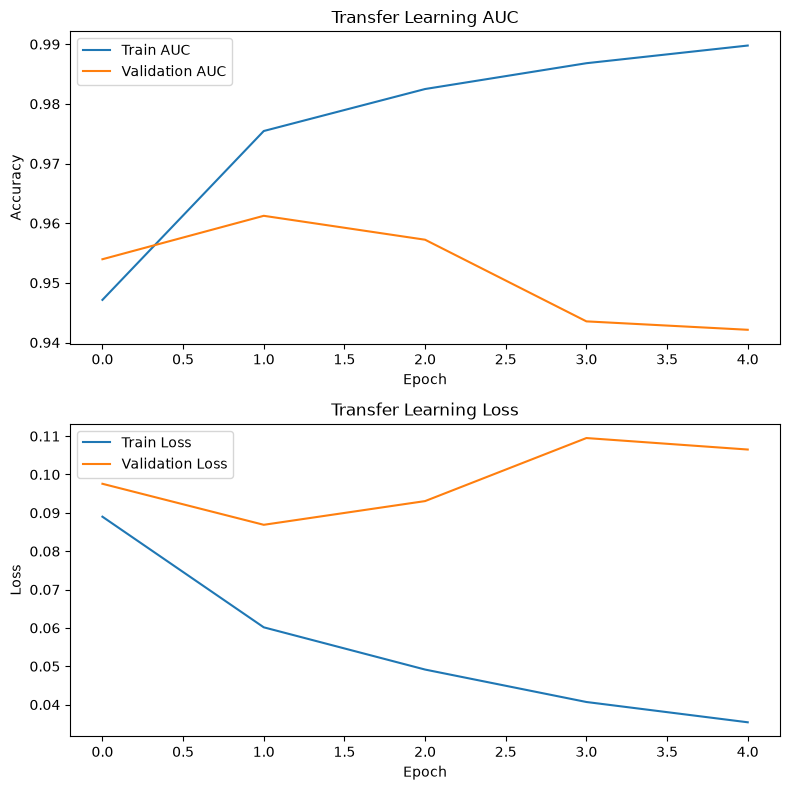

In [86]:
import matplotlib.pyplot as plt
plt.figure(figsize= (8,8))
plt.subplot(2, 1, 1)
plt.plot(his.history['auc'], label= 'Train AUC')
plt.plot(his.history['val_auc'], label= 'Validation AUC')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Transfer Learning AUC')

plt.subplot(2, 1, 2)
plt.plot(his.history['loss'], label= 'Train Loss')
plt.plot(his.history['val_loss'], label= 'Validation Loss')
plt.legend()
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.title('Transfer Learning Loss')

plt.tight_layout()
plt.savefig("transfer_learning_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Fine-tuning: unfreeze the top layers

In phase 1, the ResNet50 backbone is frozen. In phase 2, the model unfreezes the backbone and then freezes all layers except the **last 35 layers**.

- `base_model.trainable = True`: unfreezes the backbone
- `base_model.layers[:-35]`: freezes all but the final 35 layers
- `BatchNormalization` layers are kept frozen
- The printed layer flags verify which layers remain trainable

In [87]:
base_model.trainable = True
for layer in base_model.layers[:-35]:
    layer.trainable = False
    
for layer in base_model.layers:
    if isinstance(layer, layers.BatchNormalization):
        layer.trainable = False
        
for layer in base_model.layers:
    print(f'{layer.name} -> {layer.trainable}')

input_layer -> False
conv1_pad -> False
conv1_conv -> False
conv1_bn -> False
conv1_relu -> False
pool1_pad -> False
pool1_pool -> False
conv2_block1_1_conv -> False
conv2_block1_1_bn -> False
conv2_block1_1_relu -> False
conv2_block1_2_conv -> False
conv2_block1_2_bn -> False
conv2_block1_2_relu -> False
conv2_block1_0_conv -> False
conv2_block1_3_conv -> False
conv2_block1_0_bn -> False
conv2_block1_3_bn -> False
conv2_block1_add -> False
conv2_block1_out -> False
conv2_block2_1_conv -> False
conv2_block2_1_bn -> False
conv2_block2_1_relu -> False
conv2_block2_2_conv -> False
conv2_block2_2_bn -> False
conv2_block2_2_relu -> False
conv2_block2_3_conv -> False
conv2_block2_3_bn -> False
conv2_block2_add -> False
conv2_block2_out -> False
conv2_block3_1_conv -> False
conv2_block3_1_bn -> False
conv2_block3_1_relu -> False
conv2_block3_2_conv -> False
conv2_block3_2_bn -> False
conv2_block3_2_relu -> False
conv2_block3_3_conv -> False
conv2_block3_3_bn -> False
conv2_block3_add -> False

## Compile again with a low learning rate

Recompile the model after changing the trainable layers.

- `Adam(learning_rate=1e-6)`: uses a much smaller learning rate for fine-tuning
- `binary_crossentropy`: keeps the same multi-label loss
- AUC, precision, and recall are used again for evaluation

The weights are not reset by `compile`; fine-tuning continues from the transfer-learning weights.

### Compile the fine-tuning model

Recompile the model after changing the trainable layers so the fine-tuning configuration takes effect.

In [88]:
model.compile(loss= keras.losses.binary_crossentropy,
             optimizer= keras.optimizers.Adam(learning_rate= 1e-6),
             metrics= [keras.metrics.AUC(name= 'auc',multi_label= True),
                          keras.metrics.Precision(name= 'precision'),
                          keras.metrics.Recall(name= 'recal')])

## Continue training (fine-tuning)

Continue training with the partially unfrozen ResNet50.

- `base_epoch = his.epoch[-1] + 1`: starts after the phase-1 epochs
- `fine_tune_epoch = 10`: allows up to 10 fine-tuning epochs
- `epochs=main_epoch`: continues the epoch numbering from phase 1
- Early stopping monitors `val_auc` and restores the best fine-tuning weights

In the current run, fine-tuning starts at **epoch 6** and stops after **epoch 9** because validation AUC does not improve for three consecutive epochs. The best fine-tuning validation AUC is **0.9607** at epoch 6.

### Configure fine-tuning callbacks

Create early stopping and checkpoint callbacks for the fine-tuning stage.

In [89]:
fine_tune_early_stop = keras.callbacks.EarlyStopping(mode= "max", 
                                                     monitor= "val_auc", 
                                                     restore_best_weights= True,
                                                     patience= 3)

fine_tune_check_point = keras.callbacks.ModelCheckpoint("best_fine_tuning_model_parameters.keras", 
                                                        mode= max, 
                                                        monitor= "val_auc", 
                                                        save_best_only= True, 
                                                        verbose= 3)

In [90]:
base_epoch = his.epoch[-1] + 1
fine_tune_epoch = 10
main_epoch = base_epoch + fine_tune_epoch

fine_his = model.fit(train_tf, 
                     validation_data= val_tf, 
                     epochs= main_epoch, 
                     initial_epoch= base_epoch,
                     callbacks= [fine_tune_early_stop, fine_tune_check_point])

Epoch 6/15


I0000 00:00:1793714458.834585    1366 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_409488__.187


699/700 ━━━━━━━━━━━━━━━━━━━━ 0s 93ms/step - auc: 0.9857 - loss: 0.0504 - precision: 0.8710 - recal: 0.7320

I0000 00:00:1793714536.484886    1363 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_409488__.187


700/700 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/step - auc: 0.9857 - loss: 0.0503 - precision: 0.8711 - recal: 0.7320
Epoch 6: val_auc improved from None to 0.96071, saving model to best_fine_tuning_model_parameters.keras

Epoch 6: finished saving model to best_fine_tuning_model_parameters.keras
700/700 ━━━━━━━━━━━━━━━━━━━━ 133s 161ms/step - auc: 0.9857 - loss: 0.0503 - precision: 0.8711 - recal: 0.7320 - val_auc: 0.9607 - val_loss: 0.0868 - val_precision: 0.7605 - val_recal: 0.5265
Epoch 7/15
700/700 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - auc: 0.9860 - loss: 0.0487 - precision: 0.8799 - recal: 0.7304
Epoch 7: val_auc did not improve from 0.96071
700/700 ━━━━━━━━━━━━━━━━━━━━ 68s 96ms/step - auc: 0.9860 - loss: 0.0487 - precision: 0.8799 - recal: 0.7304 - val_auc: 0.9604 - val_loss: 0.0870 - val_precision: 0.7721 - val_recal: 0.5246
Epoch 8/15
700/700 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step - auc: 0.9858 - loss: 0.0476 - precision: 0.8852 - recal: 0.7323
Epoch 8: val_auc did not improve from 0.96071
700/7

### Evaluate the fine-tuned model on the training set

Measure the final fine-tuning model on the training dataset.

In [93]:
fine_train_result = model.evaluate(train_tf)
print(f"Train:\nLoss: {train_result[0]:.4f}\nAUC: {train_result[1]:.4f}\n"
         f"Precision: {train_result[2]:.4f}\nRecall: {train_result[3]:.4f}")

700/700 ━━━━━━━━━━━━━━━━━━━━ 48s 69ms/step - auc: 0.9890 - loss: 0.0459 - precision: 0.8959 - recal: 0.7357
Train:
Loss: 0.0459
AUC: 0.9890
Precision: 0.8959
Recall: 0.7357


### Evaluate the fine-tuned model on the validation set

Measure the final fine-tuning model on the validation dataset.

In [94]:
fine_val_result = model.evaluate(val_tf)
print(f"Validation:\nLoss: {val_result[0]:.4f}\nAUC: {val_result[1]:.4f}\n"
         f"Precision: {val_result[2]:.4f}\nRecall: {val_result[3]:.4f}")

66/66 ━━━━━━━━━━━━━━━━━━━━ 5s 69ms/step - auc: 0.9607 - loss: 0.0868 - precision: 0.7605 - recal: 0.5265
Validation:
Loss: 0.0868
AUC: 0.9607
Precision: 0.7605
Recall: 0.5265


### Combine the training histories

Combine the phase-1 and fine-tuning histories so both stages can be visualized on the same timeline.

In [98]:
totall_train_auc = fine_his.history['auc'] + his.history['auc']
totall_val_auc = fine_his.history['val_auc'] + his.history['val_auc']
totall_train_loss = fine_his.history['loss'] + his.history['loss']
totall_val_loss = fine_his.history['val_loss'] + his.history['val_loss']

### Plot the complete training history

Plot AUC and loss across both transfer-learning and fine-tuning stages. The vertical line marks the transition at epoch 5.

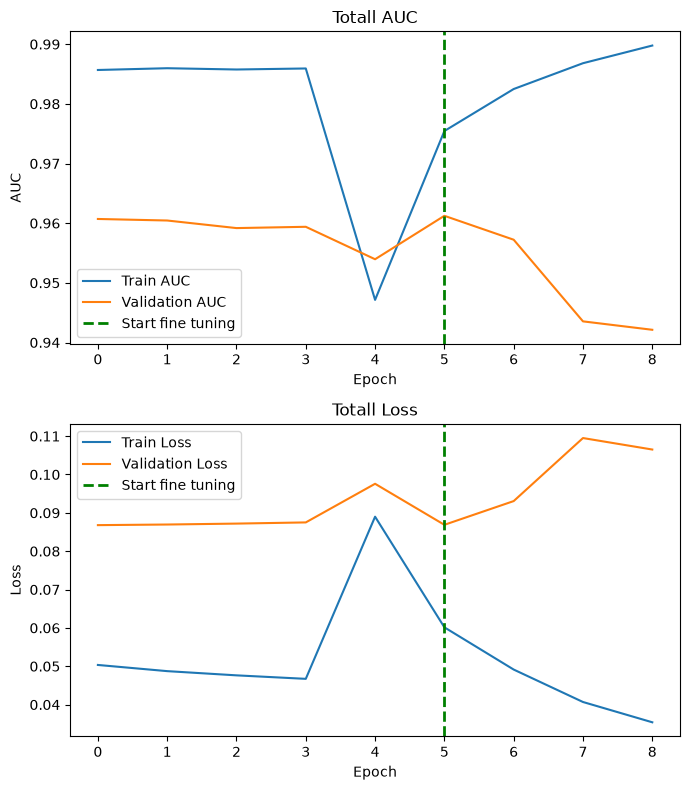

In [109]:
plt.figure(figsize= (7, 8))
plt.subplot(2, 1, 1)
plt.plot(totall_train_auc, label= "Train AUC")
plt.plot(totall_val_auc, label= "Validation AUC")
plt.axvline(x= 5, label= "Start fine tuning", color= 'green', linestyle= "--", linewidth= 2)
plt.xlabel("Epoch")
plt.ylabel("AUC")
plt.title("Totall AUC")
plt.legend()

plt.subplot(2, 1, 2)
plt.plot(totall_train_loss, label= "Train Loss")
plt.plot(totall_val_loss, label= "Validation Loss")
plt.axvline(x= 5, label= "Start fine tuning", color= "green", linestyle= "--", linewidth= 2)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Totall Loss")
plt.legend()

plt.tight_layout()
plt.show()